In the previous chapters we learned that it can be beneficial to write performance-critical (parts of) image analysis algorithms in a compiled language such as C. This chapter explains some details about the C language that you should know to write an image filter, such as the `bilateral_filter` from the previous chapter, yourself.

We'll do this by taking a closer look at the code for the `bilateral_filter`.

## The C Syntax

### Source Files, Header Files, and Includes

Whereas Python source files have the extension `.py`, C code source files typically have the extension `.c`. These files contain the implementation, or *definition*, of functions. There are also files with the extension `.h`, which are called *header files*. These header files contain function and datatype *declarations*, i.e. the C-style interface. A header files like the one below just tells: there will be a function called `bilater_filter` that returns an `int` and expects five arguments (a pointer to a `double`, a `size_t`, two `double`s, and another pointer to a `double`).

::: {#lst-example}

```c
#include <stddef.h>  // Provides size_t

//  Applies a 1-dimensional bilateral filter.
//  Returns 0 on success, -1 on invalid arguments.
int bilateral_filter(
    double *data,    // Pointer to a 1-dimensional array.
    size_t length,   // Number of elements in 'data'.
    double sigma_s,  // The spatial standard deviation of the spatial kernel (sample distance).
    double sigma_r,  // The standard deviation of the range kernel (sample values).
    double *result   // Pointer to the output array (must have at least 'length' elements).
);
```

The header file `filters.h`

:::

Similar to Python, C can import functions from other libraries. This is done by *including* the header files of these libraries. The line `#include <stddef.h>` literally means: *insert the contents of the file stddef.h at this point*. The syntax `#include <stddef.h>`, with `<>`, will search for a standard or system header file named `stddef.h`. The syntax `#include "filters.h"`, with `""`, will search for a file named `filters.h` in your own project.

The source file for our `bilateral_filter`, named e.g. `filters.c`, includes `stddef.h`, which provides the datatype `size_t`. It also includes `math.h`, which provides the declaration for the `exp()` function. It is also common practice to include our own header file, `filters.h`, because we can use this header file to declare e.g. custom datatypes.

### Functions

The general syntax for a function definition in C is:

```c
return_type function_name(arguments) {
    // Function body
    return value;
}
```

For example:

```c
double square(double x)
{
    return x * x;
}
```

In this example `double` is the return type, and `square` is the function name. The function has only one argument, `x`, of type `double`.

The *body* of the function must be given between curly brackets `{}`. Whereas Python uses 4 spaces of indentation to distinguish between a function body and other code, C does *not* take indentation or linebreaks into account. In C, indentation and linebreaks are primarily for readability. Because C ignores line breaks, we must end each statement with a semicolon (`;`)

Just like in python, a C-function can return a value using the `return` keyword. The line `return x * x;` in the function above returns the result of `x * x` as a `double`, because `double` is the return type of the function.

### Variables

Considering variables, the biggest difference is that C requires you to declare a variable with a type, whereas Python lets you create a variable simply by assigning a value to it:

::: {.panel-tabset}

## C

```c
int age = 25;
double radius = 1.75;
float factor = 1.4f;
const size_t width = 1000;
```

## Python

```python
age = 25
radius = 1.75
factor = 1.4
width = 1000
```

:::

In C, a variable's type is fixed once declared. When `age` is an int, then calling `age = 25.7;` is valid, but the value 25.7 will be cast to the integer value 25. Variables can also be declared without initializing them. The code `int age;`, for example, declares an *uninitialized* variable `age` with datatype `int`.

The C datatype `float` is a 32-bit floating point value, corresponding to `np.float32` in NumPy. To explicitly enter a `float` value, the number should end with an `f`, like `float factor = 1.4f;`.

The value for variables that are declared `const`, like `const size_t width = 1000;`, can not be changed. Accidentally doing so will make the compilation fail.

One more thing to pay attention to, is that variables might need to be converted to another, suitable datatype for a specific calculation. If datatypes are not suited for a calculation, such as dividing integer values for which the result is not an integer, or subtracting unsigned integers for which the result is negative, then we should first convert the types. Variables can be explicitly converted to another type like this: `(double)age`, which casts the integer `age` to a `double`. When you perform a calculation involving multiple datatypes, then C will implicitly convert one if necessary. When both have the same datatype, C will not convert them:

* `double x = 2 / 3;` is 0.0, because 2 and 3 are integers. C performs integer division `2 / 3` first, for which the result is 0.
* `double y = 2.0 / 3;` is approximately 0.666667, because 2.0 is a double. C will implicitly convert the integer 3 to a double and perform a floating point division.
* When subtracting two unsigned integers, e.g. of type `size_t`, then the result might wrap, just like in NumPy:

In [29]:
import numpy as np


width = np.uint64(1000)
k = np.uint64(3)

print(f"{k} - {width} = {k - width}")

3 - 1000 = 18446744073709550619


C:\Users\hbennink\AppData\Local\Temp\ipykernel_34320\1294873051.py:7: RuntimeWarning: overflow encountered in scalar subtract
  print(f"{k} - {width} = {k - width}")


### If-Statements

If-statements in C are very similar to if-statements in Python. The differences are that C encloses the condition in parentheses (`()`), and the body of the statement in curly brackets `{}`, whereas Python requires a colon (`:`) to end the condition, and 4 spaces of indentation for the body. The C language also uses `else if` instead of `elif`. Below is an example of an `if`, `else if`, `else` block in C and in Python:

::: {.panel-tabset}

## C

```c
if (x > 0) {
    printf("Positive");
} else if (x < 0) {
    printf("Negative");
} else {
    printf("Zero");
}
```

## Python

```python
if x > 0:
    print("Positive")
elif x < 0:
    print("Negative")
else:
    print("Zero")

```

:::

The operators used for equality are these:

| Operation   | C      | Python |
|-------------|--------|--------|
| Equal       | `==`   | `==`   |
| Not equal   | `!=`   | `!=`   |
| Logical AND | `&&`   | `and`  |
| Logical OR  | `||` | `or`   |
| Logical NOT | `!`    | `not`  |

Both Python and C also support the [*ternary operator*](https://en.wikipedia.org/wiki/Ternary_conditional_operator). C uses the syntax `a ? b : c`, which reads as *if a then b else c*. In Python, the syntax is `b if a else c`. The Python operation `x = min(a, b)` can be written in C as:

```c
x = a < b ? a : b;
```

### For-Loops

Whereas Python's `for` allows iterating over items in a list, a tuple, or any other *iterable* object, a C `for` loop is built around initialization, a condition, and an update expression. Suppose you want to sum up the values in an array of length `n`:

::: {.panel-tabset}

## C

```c
double sum = 0.0;
for (int i = 0; i < n; i++) {
    sum += data[i];
}
```

## Python

```python
sum = 0
for i in range(n):
    sum += data[i]

```

:::

The C loop has three parts inside the parentheses, separated by a semicolon (`;`):

* **Initialization**: `int i = 0` runs once at the beginning, and declares a new integer variable `i`, which is initialized to 0.
* **Condition**: `i < n` is checked before every iteration. When it is true then it continues iterating. When it is false, then the iteration stops.
* **Update**: `i++` runs after each iteration, where `i++` is shorthand notation for `i = i + 1`.

Just like in Python, a C `for` loop can be stopped using the `break` keyword, and iteration can be skipped with `continue`.

And again, C uses curly braces (`{}`) to enclose a `for`-loop body. What is also different from Python, is that variables that are declared inside a C `for`-loop are scoped to that loop. They don't exist outside the loop and thus cannot be used after the loop ends. Variables that exist outside the `for`-loop can, of course, be used inside the loop.

## Computer Memory and Pixel Values

Before learning how to work with one-dimensional arrays and 2D and 3D pixel data in C, it helps to understand a little more about how computer memory works.

It helps to think of computer memory as a huge one-dimensional array of numbers. When we create a new one-dimensional NumPy array, it is most often allocated in such a way that adjacent values in the array are also adjacent in the computer memory. When we create a two-dimensional array, then it is most often allocated in such a way that all rows are adjacent in memory too. Take an image with `nx` columns and `ny` rows. Counting from zero, array index `nx-1` is the value of the last pixel in the first row, and array index `nx` is the value of the first pixel in the second row. Like this:

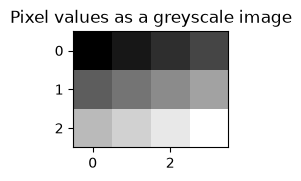

The pixel values values as a matrix:
 [[  0  10  20  30]
 [ 40  50  60  70]
 [ 80  90 100 110]]

The pixel values in computer memory:
 [  0  10  20  30  40  50  60  70  80  90 100 110]


In [41]:
import matplotlib.pyplot as plt


image_2d = np.array([[0, 10, 20, 30], [40, 50, 60, 70], [80, 90, 100, 110]])
image_1d = image_2d.ravel()  # 'ravel()' return a contiguous flattened array.

fig, ax = plt.subplots(figsize=(2, 2))
ax.imshow(image_2d, cmap='gray')
plt.title("Pixel values as a greyscale image")
plt.show()

print("The pixel values values as a matrix:\n", image_2d)

print("\nThe pixel values in computer memory:\n", image_1d)

To lookup pixel values in this one dimensional array, we must calculate the index ourselves

In [39]:
ny, nx = image_2d.shape

for y in range(ny):
    for x in range(nx):
        i = y * nx + x
        print(f"Coordinate ({x}, {y}), index {i}, pixel value: {image_1d[i]}")

Coordinate (0, 0), index 0, pixel value: 0
Coordinate (1, 0), index 1, pixel value: 10
Coordinate (2, 0), index 2, pixel value: 20
Coordinate (3, 0), index 3, pixel value: 30
Coordinate (0, 1), index 4, pixel value: 40
Coordinate (1, 1), index 5, pixel value: 50
Coordinate (2, 1), index 6, pixel value: 60
Coordinate (3, 1), index 7, pixel value: 70
Coordinate (0, 2), index 8, pixel value: 80
Coordinate (1, 2), index 9, pixel value: 90
Coordinate (2, 2), index 10, pixel value: 100
Coordinate (3, 2), index 11, pixel value: 110


Fetching pixel values from computer memory is fastest when values are accessed sequentially. *Linear memory access* can be 2 orders of magnitude (100×) faster than random access! This is the reason why we should *always* iterate over rows (along the x-dimension) in the inner `for`-loop. Swapping the loops disrupts sequential memory access and can significantly reduce performance:

In [40]:
for x in range(nx):
    for y in range(ny):
        i = y * nx + x
        print(f"Coordinate ({x}, {y}), index {i}, pixel value: {image_1d[i]}")

Coordinate (0, 0), index 0, pixel value: 0
Coordinate (0, 1), index 4, pixel value: 40
Coordinate (0, 2), index 8, pixel value: 80
Coordinate (1, 0), index 1, pixel value: 10
Coordinate (1, 1), index 5, pixel value: 50
Coordinate (1, 2), index 9, pixel value: 90
Coordinate (2, 0), index 2, pixel value: 20
Coordinate (2, 1), index 6, pixel value: 60
Coordinate (2, 2), index 10, pixel value: 100
Coordinate (3, 0), index 3, pixel value: 30
Coordinate (3, 1), index 7, pixel value: 70
Coordinate (3, 2), index 11, pixel value: 110


One more thing to pay attention to, is that C doesn't know about the size of arrays. It cannot check if the index is actually in or *out of bounds* of the array! A C function will *not* raise an `IndexError` like Python does. Because a C-style pointer corresponds to a memory address, reading or writing a memory location that is out of bounds could have different outcomes. An attempt to read or write in a memory *segment* that is not readable or writeable by our Python *process* will terminate the application; Python 'crashes' with a [*segmentation fault*](https://en.wikipedia.org/wiki/Segmentation_fault). Reading and writing in memory segments that *do* belong to our Python process result in undefined behavior.

### Iterating Over Pixel Data

Now we know about `for`-loops, variables, and arrays in C, we can apply this knowledge to iterate over e.g. 3-dimensional images. Putting it all together, a C function that applies a 3x3 mean filter to a 2D image could look like this:

```c
#include "filters.h"

#include <stddef.h>  // Provides NULL and size_t


//  Applies a 3x3 mean filter to a 2D image.
//  Returns 0 on success, -1 on invalid arguments.
int mean_filter_3x3(
    const double *data,  // Pointer to a 2-dimensional image (input)
    double *result,      // Pointer to a 2-dimensional image (output)
    const size_t nx,     // Image width
    const size_t ny      // Image height
) {
    if (data == NULL || result == NULL) {
        return -1;
    }

    // Iterate over all rows and colums in the 2D image.
    for (size_t y = 0; y < ny; y++) {
        const size_t y_start = (y > 0) ? y - 1 : 0;          // max(y - 1, 0)
        const size_t y_end = (y < ny - 1) ? y + 1 : ny - 1;  // min(y + 1, ny - 1)

        for (size_t x = 0; x < nx; x++) {
            double sum = 0.0;  // Sum of pixel values in the 3x3 neighborhood for pixel (x, y).

            const size_t x_start = (x > 0) ? x - 1 : 0;          // max(x - 1, 0)
            const size_t x_end = (x < nx - 1) ? x + 1 : nx - 1;  // min(x + 1, nx - 1)

            for (size_t ky = y_start; ky <= y_end; ky++) {
                for (size_t kx = x_start; kx <= x_end; kx++) {
                    sum += data[ky * nx + kx];  // Add the value of pixel (kx, ky) to the sum.
                }
            }

            result[y * nx + x] = sum / 9;  // Calculate the mean.
        }
    }

    return 0;
}
```

## Executables

When C-files contain an *entrypoint* function, they can be compiled into an executable program, or simply *executable*. On Windows, these files have the extension `.exe`. On Linux and macOS, executables generally have no extension. The entrypoint function is always called `main()` and must have the return type `int`. The return value for `main()` is known as the `exit code` and should be 0 when the program executed succesfully.

A simple C program that just prints `Hello World!` when it is compiled and executed looks like this:

```c
#include <stdio.h>  // Provides printf()

int main() {
    printf("Hello World!");
    return 0;
}
```

## Try It Out Yourself

> **External course material**
>
> Review these pages and do the exercises:
>
> * <https://www.w3schools.com/c/c_syntax.php>
> * <https://www.w3schools.com/c/c_challenges_syntax.php>
> * <https://www.w3schools.com/c/c_data_types_numbers.php>
> * <https://www.w3schools.com/c/c_type_conversion.php>
> * <https://www.w3schools.com/c/c_conditions_elseif.php>
> * <https://www.w3schools.com/c/c_for_loop.php>
> * <https://www.w3schools.com/c/c_ref_math.php>

## Assignments
You've reached the end of this week's study material! During Friday's practical session, we'll start working on the first part of the third graded assignment. This group assignment, which you will be making with a new group, is handed out on Friday.

We will be using the 'gcc' C compiler. Instructions on how to install gcc will follow.